In [5]:
# Download the dataset from Kaggle (requires kaggle.json API key in ~/.kaggle/ or C:/Users/<YourUsername>/.kaggle/)
# Install kaggle package if not already installed:
!pip install kaggle

# Download and unzip the dataset into the data folder:
!kaggle datasets download -d mlg-ulb/creditcardfraud -p data --unzip

Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
License(s): DbCL-1.0




  0%|          | 0.00/66.0M [00:00<?, ?B/s]
 88%|████████▊ | 58.0M/66.0M [00:00<00:00, 592MB/s]
100%|██████████| 66.0M/66.0M [00:00<00:00, 583MB/s]


In [6]:
import os
os.makedirs('reports', exist_ok=True)
os.makedirs('models', exist_ok=True)

In [3]:
import pandas as pd
import numpy as np

# Load the dataset
file_path = 'data/creditcard.csv'
df = pd.read_csv(file_path)

# View top records
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import joblib

In [2]:
     import sys
     print(sys.executable)

c:\Users\mohit\Desktop\M.tech\PROJECT\venv\Scripts\python.exe


In [4]:
print("Shape of dataset:", df.shape)
print("\nData types and missing values:\n")
print(df.info())

Shape of dataset: (284807, 31)

Data types and missing values:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-nul

In [5]:
print("\nClass distribution:")
print(df['Class'].value_counts())
print("\nClass distribution (%):")
print(df['Class'].value_counts(normalize=True) * 100)


Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class distribution (%):
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [6]:
from sklearn.preprocessing import StandardScaler

# Scale the 'Amount' column
scaler = StandardScaler()
df['Amount_scaled'] = scaler.fit_transform(df[['Amount']])

# Drop original 'Time' and 'Amount' columns
df.drop(['Time', 'Amount'], axis=1, inplace=True)

In [7]:
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

In [ ]:
# Install advanced libraries if not already installed
!pip install xgboost catboost lightgbm shap

In [8]:


from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# Hyperparameter tuning using GridSearchCV (example for Random Forest)
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10],
    'class_weight': ['balanced']
}

print("\nRunning GridSearchCV for Random Forest...")
rf_grid = GridSearchCV(RandomForestClassifier(), rf_params, scoring='roc_auc', cv=3)
rf_grid.fit(X_train, y_train)
print("Best parameters for Random Forest:", rf_grid.best_params_)

# Use tuned model
best_rf = rf_grid.best_estimator_

# Define models (with tuned RF)
models = {
    'XGBoost': XGBClassifier(
        scale_pos_weight=100,
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        use_label_encoder=False,
        eval_metric='logloss'
    ),
    'LightGBM': LGBMClassifier(class_weight='balanced', n_estimators=100),
    'CatBoost': CatBoostClassifier(verbose=0, iterations=100, class_weights=[1, 100]),
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000),
    'Random Forest': best_rf,
    'SVM': SVC(kernel='rbf', class_weight='balanced', probability=True),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1)
}

# Train all models
trained_models = {}
for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)
    trained_models[name] = model 


Running GridSearchCV for Random Forest...
Best parameters for Random Forest: {'class_weight': 'balanced', 'max_depth': 10, 'n_estimators': 200}

Training XGBoost...


c:\Users\mohit\Desktop\M.tech\PROJECT\venv\Lib\site-packages\xgboost\training.py:183: UserWarning: [17:52:58] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Training LightGBM...
[LightGBM] [Info] Number of positive: 394, number of negative: 227451
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.087052 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7395
[LightGBM] [Info] Number of data points in the train set: 227845, number of used features: 29
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000

Training CatBoost...

Training Logistic Regression...

Training Random Forest...

Training SVM...

Training Gradient Boosting...



Evaluation for XGBoost:
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.77      0.87      0.82        98

    accuracy                           1.00     56962
   macro avg       0.89      0.93      0.91     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
 [[56839    25]
 [   13    85]]
ROC-AUC Score: 0.9786060439229152

Evaluation for LightGBM:
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.82      0.85      0.83        98

    accuracy                           1.00     56962
   macro avg       0.91      0.92      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
 [[56846    18]
 [   15    83]]
ROC-AUC Score: 0.9705365756319411

Evaluation for CatBoost:
Classification Report:
               precision    re

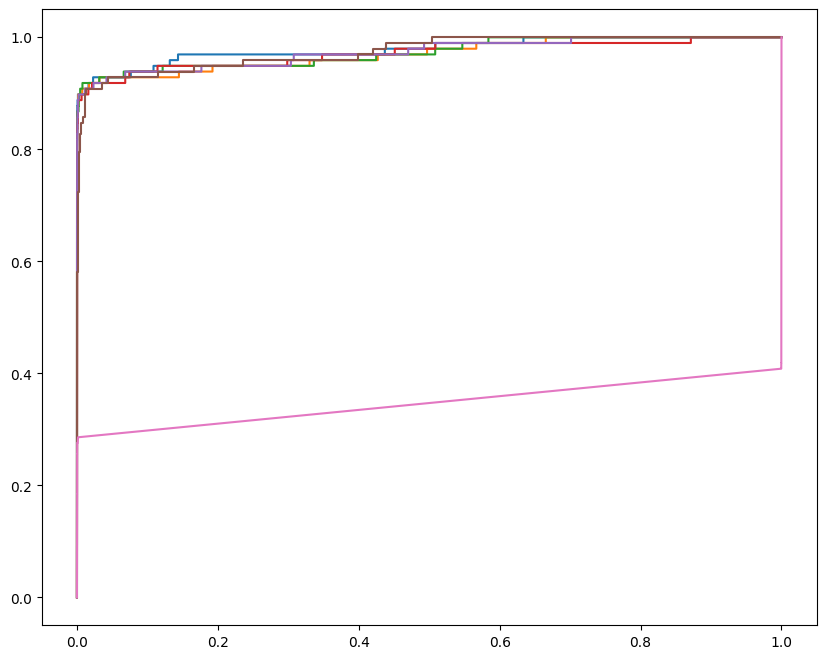

In [9]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
eval_metrics = []

for name, model in trained_models.items():
    print(f"\nEvaluation for {name}:")
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    report = classification_report(y_test, y_pred, output_dict=True)
    cm = confusion_matrix(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_proba)
    print("Classification Report:\n", classification_report(y_test, y_pred))
    print("Confusion Matrix:\n", cm)
    print("ROC-AUC Score:", auc_score)

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_score:.2f})")

    eval_metrics.append({
        'Model': name,
        'Precision': report['1']['precision'],
        'Recall': report['1']['recall'],
        'F1-Score': report['1']['f1-score'],
        'AUC': auc_score
    })


Training Ensemble Voting Classifier...


c:\Users\mohit\Desktop\M.tech\PROJECT\venv\Lib\site-packages\xgboost\training.py:183: UserWarning: [19:46:52] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Evaluation for Ensemble:
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.72      0.88      0.79        98

    accuracy                           1.00     56962
   macro avg       0.86      0.94      0.89     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
 [[56830    34]
 [   12    86]]
ROC-AUC Score: 0.9726972985311176


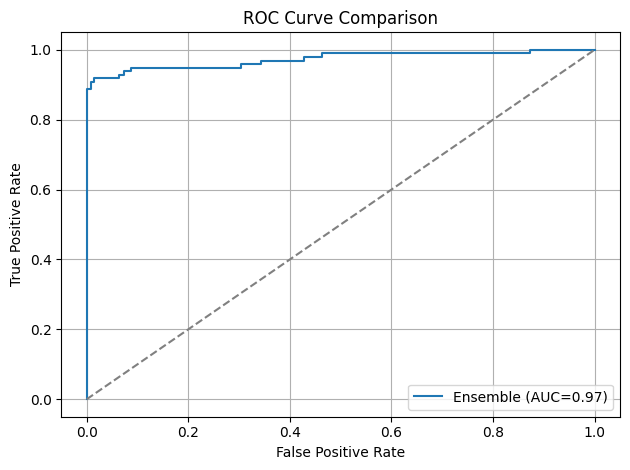

In [10]:
print("\nTraining Ensemble Voting Classifier...")
ensemble_model = VotingClassifier(
    estimators=[
        ('lr', models['Logistic Regression']),
        ('rf', models['Random Forest']),
        ('xgb', models['XGBoost']),
        ('gb', models['Gradient Boosting'])
    ],
    voting='soft'
)
ensemble_model.fit(X_train, y_train)

# Evaluate Ensemble
print("\nEvaluation for Ensemble:")
y_pred_ensemble = ensemble_model.predict(X_test)
y_proba_ensemble = ensemble_model.predict_proba(X_test)[:, 1]
report = classification_report(y_test, y_pred_ensemble, output_dict=True)
auc_score = roc_auc_score(y_test, y_proba_ensemble)
print("Classification Report:\n", classification_report(y_test, y_pred_ensemble))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ensemble))
print("ROC-AUC Score:", auc_score)

fpr, tpr, _ = roc_curve(y_test, y_proba_ensemble)
plt.plot(fpr, tpr, label=f"Ensemble (AUC={auc_score:.2f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('reports/roc_curve_comparison.png')
plt.show()

# Add Ensemble to Evaluation Table
eval_metrics.append({
    'Model': 'Ensemble',
    'Precision': report['1']['precision'],
    'Recall': report['1']['recall'],
    'F1-Score': report['1']['f1-score'],
    'AUC': auc_score
})

In [11]:
summary_df = pd.DataFrame(eval_metrics)
summary_df = summary_df.sort_values(by='AUC', ascending=False)
print("\nModel Performance Comparison:")
print(summary_df)
summary_df.to_csv('reports/model_performance_summary.csv', index=False)


Model Performance Comparison:
                 Model  Precision    Recall  F1-Score       AUC
0              XGBoost   0.772727  0.867347  0.817308  0.978606
5                  SVM   0.296154  0.785714  0.430168  0.974426
4        Random Forest   0.771429  0.826531  0.798030  0.973347
2             CatBoost   0.828283  0.836735  0.832487  0.973032
7             Ensemble   0.716667  0.877551  0.788991  0.972697
3  Logistic Regression   0.058785  0.918367  0.110497  0.971447
1             LightGBM   0.821782  0.846939  0.834171  0.970537
6    Gradient Boosting   0.529412  0.183673  0.272727  0.346886


c:\Users\mohit\Desktop\M.tech\PROJECT\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Generating SHAP summary plot...


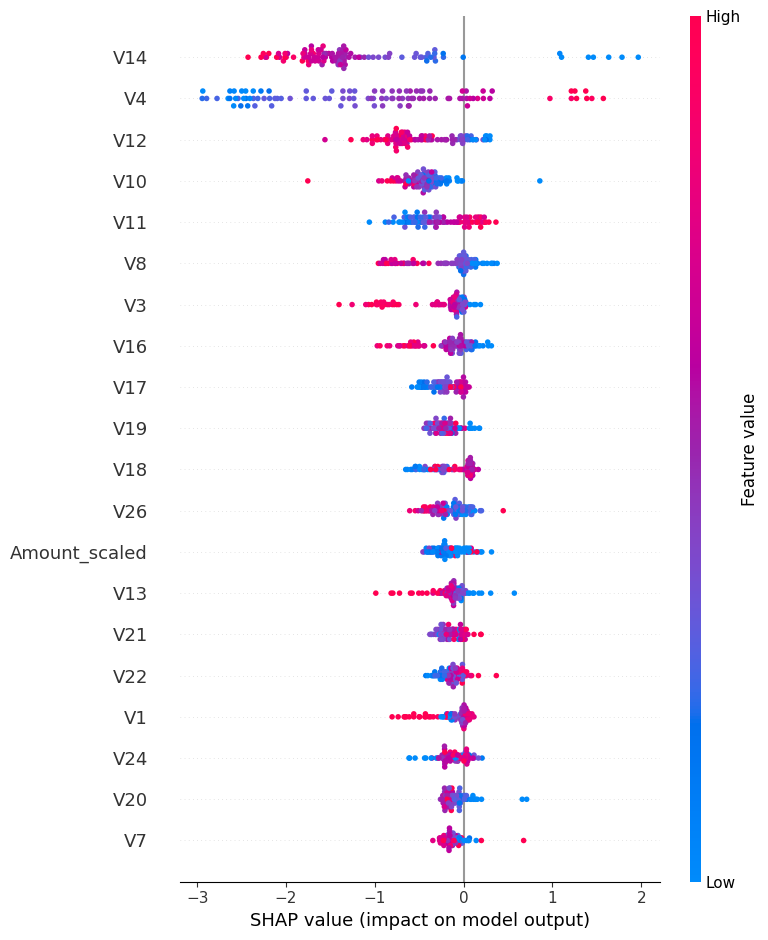

In [12]:
import shap
explainer = shap.Explainer(ensemble_model.named_estimators_['xgb'])
shap_values = explainer(X_test[:100])

print("\nGenerating SHAP summary plot...")
shap.summary_plot(shap_values, X_test[:100])

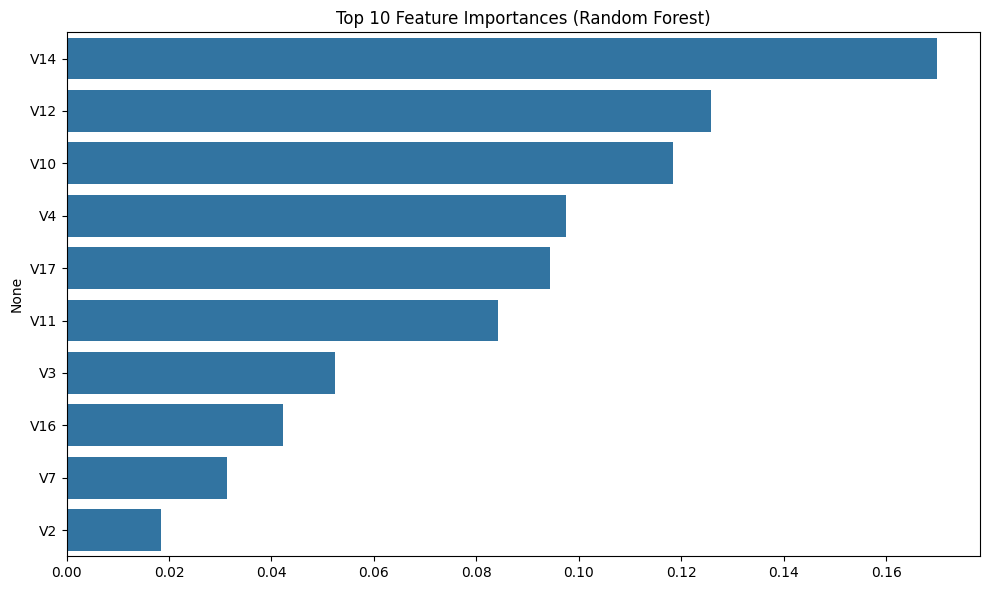

In [13]:
import seaborn as sns

plt.figure(figsize=(10, 6))
importances = best_rf.feature_importances_
indices = np.argsort(importances)[::-1][:10]
plt.title("Top 10 Feature Importances (Random Forest)")
sns.barplot(x=importances[indices], y=X.columns[indices])
plt.tight_layout()
plt.savefig('reports/feature_importance_rf.png')
plt.show()

In [14]:
import joblib

best_model = ensemble_model  # Based on evaluation, change as needed
model_save_path = 'models/best_model.pkl'
joblib.dump(best_model, model_save_path)
print(f"Model saved to {model_save_path}")

Model saved to models/best_model.pkl


In [15]:
from matplotlib.backends.backend_pdf import PdfPages

with PdfPages('reports/evaluation_report.pdf') as pdf:
    # ROC curve
    fig1 = plt.figure()
    plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
    for name, model in trained_models.items():
        y_proba = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, y_proba):.2f})")
    plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
    plt.title('ROC Curve Comparison')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend()
    plt.grid(True)
    pdf.savefig(fig1)
    plt.close()

    # Feature importance
    fig2 = plt.figure()
    sns.barplot(x=importances[indices], y=X.columns[indices])
    plt.title("Top 10 Feature Importances (Random Forest)")
    plt.tight_layout()
    pdf.savefig(fig2)
    plt.close()

    # Summary table
    fig3 = plt.figure()
    sns.heatmap(summary_df.set_index('Model'), annot=True, fmt=".2f", cmap="Blues")
    plt.title("Model Performance Summary")
    pdf.savefig(fig3)
    plt.close()

print("Evaluation report saved to 'reports/evaluation_report.pdf'")

Evaluation report saved to 'reports/evaluation_report.pdf'
